# 03 · Findings

The five questions, answered from `results/`. The same text is generated as `results/findings.md`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import UNIVERSE, FX_TICKER, RESULTS_DIR
from src.reporting import charts
R = lambda name: pd.read_csv(RESULTS_DIR / name)
import plotly.io as pio
pio.renderers.default = "png"  # static images so the notebooks render on GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 900, 480

In [2]:
from IPython.display import Markdown
Markdown((RESULTS_DIR / 'findings.md').read_text())

# Findings (auto-generated by `python -m src.pipeline`)

Sample: 2026-10-19 to 2026-11-13, 20 sessions of 1-minute bars (yfinance). Costs in bps, positive = cost. Simulated buys and sells pooled.

## Q1. Cost of executing 1/5/10/20% of ADV, by algorithm

Mean implementation shortfall of a full-session **VWAP** order:

| ticker | 1% ADV | 5% ADV | 10% ADV | 20% ADV |
|---|---|---|---|---|
| AAPL | 13.9 | 28.4 | 38.0 | 49.5 |
| AMXB | 21.6 | 42.0 | 54.3 | 67.8 |
| GFNORTEO | 15.1 | 30.9 | 40.8 | 52.1 |
| GMEXICOB | 23.6 | 48.4 | 63.8 | 81.2 |
| IVV | 8.5 | 17.4 | 23.0 | 29.4 |
| NAFTRAC | 39.7 | 46.4 | 49.4 | 52.2 |
| WALMEX | 15.4 | 31.1 | 40.9 | 52.0 |

Cheapest and lowest-risk algorithm among those that complete (fill > 99%):

| ticker | pct_adv | algo_cheapest | is_total_bps | algo_lowest_risk | is_std_bps |
|---|---|---|---|---|---|
| AAPL | 1% | VWAP | 13.9 | POV20 | 38.2 |
| AAPL | 5% | VWAP | 28.4 | POV20 | 66.5 |
| AAPL | 10% | VWAP | 38.0 | POV20 | 80.6 |
| AAPL | 20% | VWAP | 49.5 | IS | 99.2 |
| AMXB | 1% | VWAP | 21.6 | POV20 | 64.5 |
| AMXB | 5% | VWAP | 42.0 | POV20 | 107.2 |
| AMXB | 10% | VWAP | 54.3 | IS | 138.7 |
| AMXB | 20% | VWAP | 67.8 | IS | 138.7 |
| GFNORTEO | 1% | VWAP | 15.1 | POV20 | 58.0 |
| GFNORTEO | 5% | VWAP | 30.9 | IS | 76.9 |
| GFNORTEO | 10% | VWAP | 40.8 | IS | 76.9 |
| GFNORTEO | 20% | VWAP | 52.1 | IS | 76.9 |
| GMEXICOB | 1% | VWAP | 23.6 | POV20 | 97.9 |
| GMEXICOB | 5% | VWAP | 48.4 | IS | 99.9 |
| GMEXICOB | 10% | VWAP | 63.8 | IS | 99.9 |
| GMEXICOB | 20% | VWAP | 81.2 | IS | 99.9 |
| IVV | 1% | VWAP | 8.5 | POV20 | 17.1 |
| IVV | 5% | VWAP | 17.4 | POV20 | 48.7 |
| IVV | 10% | VWAP | 23.0 | IS | 70.3 |
| IVV | 20% | VWAP | 29.4 | IS | 70.3 |
| NAFTRAC | 1% | VWAP | 39.7 | IS | 51.9 |
| NAFTRAC | 5% | VWAP | 46.4 | IS | 51.9 |
| NAFTRAC | 10% | VWAP | 49.4 | IS | 51.9 |
| NAFTRAC | 20% | VWAP | 52.2 | IS | 51.8 |
| WALMEX | 1% | VWAP | 15.4 | POV20 | 82.9 |
| WALMEX | 5% | VWAP | 31.1 | IS | 116.9 |
| WALMEX | 10% | VWAP | 40.9 | IS | 116.9 |
| WALMEX | 20% | VWAP | 52.0 | IS | 116.9 |

POV orders that could not complete within the session: 36 of 56 ticker-size cells (e.g. POV10 at 20% ADV fills 14-98%); their remainder is charged drift-to-close plus the next-day pre-trade cost.

## Q2. Mexico vs US

| market | spread_bps | usd_per_bp | adv_usd_m | exec_cov | daily_vol_bps | vwap_5pct_bps |
|---|---|---|---|---|---|---|
| MX | 2.37 | 10,694.05 | 45.16 | 0.49 | 137.48 | 41.99 |
| US | 1.81 | 4,370,423.36 | 10,274.93 | 0.56 | 116.49 | 22.89 |

- Median depth proxy: US names absorb **409x** more USD per bp of 1-minute price move than MX names.
- Median spread estimate: MX 2.37 bps vs US 1.81 bps (US estimates are upper bounds: at 1-min frequency Corwin-Schultz is inflated by intra-minute volatility; a 1-cent quote on AAPL is ~0.3 bps).
- Only 49% of MX official daily volume is visible as executable continuous-session volume in yfinance bars (US: 56%): the rest is auctions, very large prints (likely block crosses) and, for BMV, the last trading hour that yfinance does not serve.
- Same %ADV costs about the same in the square-root model when volatility is similar - but 5% of ADV is USD 2.3m in the median MX name vs USD 514m in the US.

## Q3. Intraday liquidity

- **MX**: first 30 min spread 5.60 bps vs 3.46 bps mid-session (1.6x); largest volume bucket starts +6.0 h (23.7% of volume); tightest spread at +2.5 h.
- **US**: first 30 min spread 3.55 bps vs 1.12 bps mid-session (3.2x); largest volume bucket starts +6.0 h (15.6% of volume); tightest spread at +4.0 h.

## Q4. Impact vs timing risk (Almgren-Chriss), GFNORTEO 10% ADV

| label | cost_bps | risk_bps | fill_rate |
|---|---|---|---|
| IS u=0 | 42.9 | 95.3 | 1.0 |
| IS u=1 | 43.4 | 91.4 | 1.0 |
| IS u=2 | 45.6 | 83.6 | 1.0 |
| IS u=3 | 49.0 | 76.9 | 1.0 |
| IS u=5 | 55.8 | 69.0 | 1.0 |
| IS u=8 | 62.8 | 62.5 | 1.0 |
| IS u=12 | 68.5 | 57.3 | 1.0 |
| VWAP | 40.8 | 97.0 | 1.0 |
| POV10 | 26.2 | 122.6 | 0.6 |
| POV20 | 40.6 | 98.3 | 0.9 |

- Moving from TWAP (urgency 0) to IS urgency 3: cost 42.9 -> 49.0 bps (+6.1), risk 95.3 -> 76.9 bps (-19%).
- Calibration: sigma per bar 8.34 bps, linear temp-impact eta 14456 bps, N = 389 bars.

## Q5. Spread estimators vs truth

Synthetic bars with known spread (estimate / true, daily level, mean over spreads 2-20 bps and 5 seeds):

| trades_per_minute | cs_bps | cs_clip_of_mean_bps | roll_bps |
|---|---|---|---|
| 2.00 | 0.15 | 0.04 | 1.10 |
| 5.00 | 0.51 | 0.16 | 1.13 |
| 10.00 | 0.83 | 0.29 | 1.09 |
| 30.00 | 1.12 | 0.50 | 1.08 |
| 100.00 | 1.33 | 0.76 | 0.98 |

Bloomberg validation: **pending** (no files in `data/raw/bbg/`).

## Impact-coefficient sensitivity (pre-trade model, 10% ADV)

| ticker | k=0.5 | k=0.7 | k=1.0 |
|---|---|---|---|
| AAPL | 23.3 | 32.0 | 45.2 |
| AMXB | 27.3 | 37.3 | 52.4 |
| GFNORTEO | 22.0 | 30.5 | 43.3 |
| GMEXICOB | 33.4 | 46.3 | 65.7 |
| IVV | 15.4 | 21.3 | 30.3 |
| NAFTRAC | 16.4 | 21.4 | 28.8 |
| WALMEX | 22.9 | 31.6 | 44.7 |


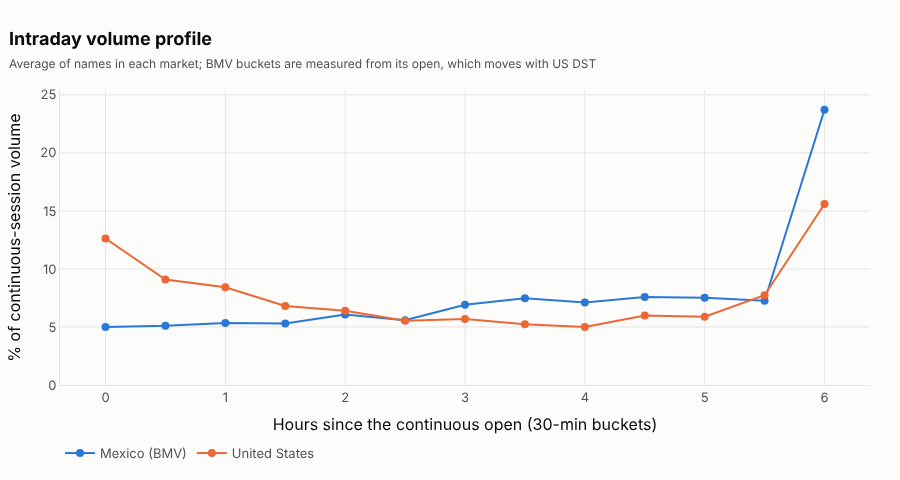

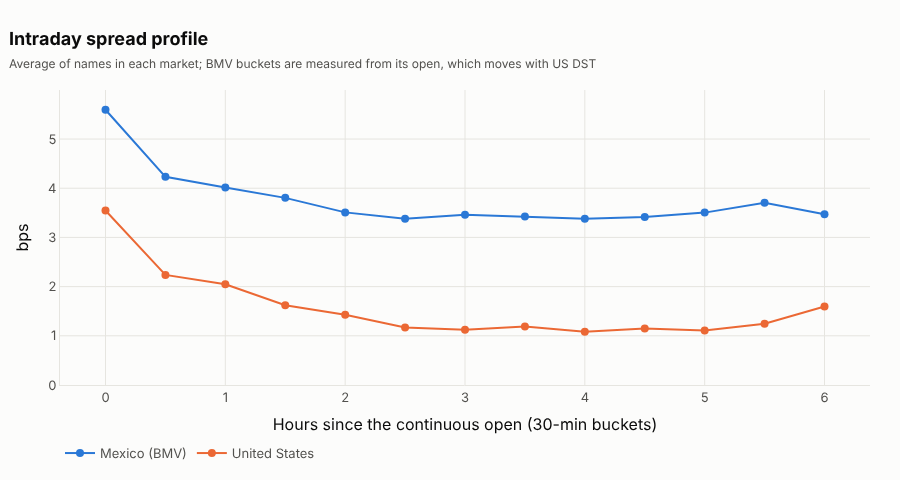

In [3]:
prof = R('intraday_profile.csv')
charts.intraday_profile(prof, 'volume_share').show()
charts.intraday_profile(prof, 'spread_bps').show()

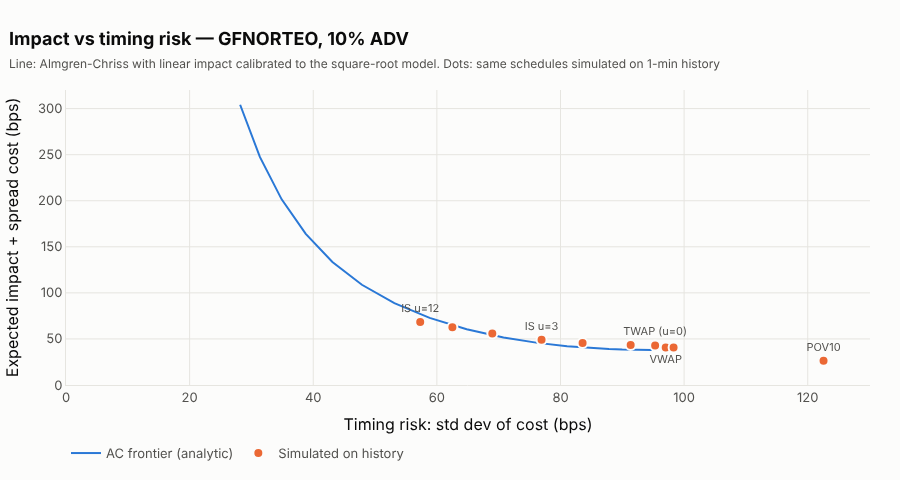

In [4]:
charts.ac_frontier_chart(R('ac_frontier.csv'), R('ac_simulated.csv'), 'GFNORTEO.MX').show()

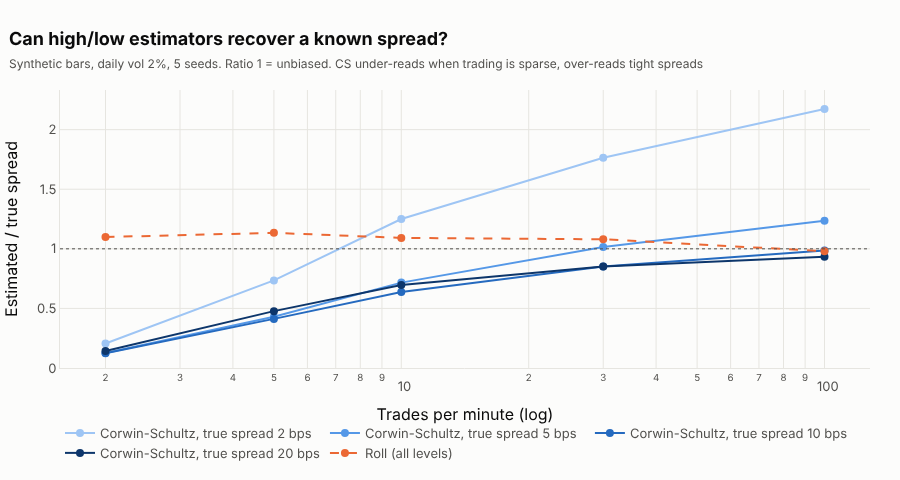

In [5]:
charts.estimator_recovery(R('synthetic_validation.csv')).show()

## Bloomberg validation (Q5)

Runs automatically when `data/raw/bbg/<STEM>_1min.csv` files exist (never committed).

In [6]:
p = RESULTS_DIR / 'bbg_validation.csv'
R('bbg_validation.csv') if p.exists() else 'Pending: no Bloomberg files yet.'

'Pending: no Bloomberg files yet.'